# Preparación y análisis del dataset Beans

**Asignatura:** Inteligencia Artificial  
**Proyecto:** Clasificación de enfermedades foliares de fréjol  
**Grupo:** 1

## Objetivo

Analizar las clases, la distribución y las imágenes del dataset Beans, y
preparar sus particiones para entrenar y comparar la CNN propia, MobileNetV2,
EfficientNetB0 y DenseNet121.

In [1]:
# PASO 1: Importación y verificación de librerías
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

# Mostrar las versiones utilizadas en el notebook.
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("NumPy:", np.__version__)

# Consultar los dispositivos que TensorFlow puede usar.
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("\nLibrerías importadas correctamente.")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
NumPy: 2.5.4
GPU disponible: []

Librerías importadas correctamente.


In [3]:
# PASO 2: Carga de las particiones oficiales de Beans
from zipfile import ZipFile

# Usar la copia de los ZIP originales publicada por Makerere AI Lab.
url_base = (
    "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/"
    "27aa014ce09b193e1a6f58112d4a66e0eddb69c5/data/"
)

# Verificar que cada descarga coincide con el archivo original.
huellas_sha256 = {
    "train": "284fe8456ce20687f4367ae7ad94a64577e7f9fde2c2c6b1c74340ab5dc82715",
    "validation": "90b7aa1c26d91d9afff07a30bbc67a5ea34f1f1397f068d8675be09d7d0c602d",
    "test": "ca67b15d960d1e2fd9d23fd8498ce86818ead90755c630a43baf19ec4af09312",
}

# Mantener el mismo orden de etiquetas que usa TensorFlow Datasets.
clases = ["angular_leaf_spot", "bean_rust", "healthy"]
id_por_clase = {nombre: indice for indice, nombre in enumerate(clases)}


def cargar_particion(nombre):
    ruta_zip = tf.keras.utils.get_file(
        fname=f"{nombre}.zip",
        origin=f"{url_base}{nombre}.zip",
        file_hash=huellas_sha256[nombre],
        hash_algorithm="sha256",
        cache_subdir="datasets/beans_makerere",
    )

    with ZipFile(ruta_zip) as archivo:
        fotos = sorted(ruta for ruta in archivo.namelist() if ruta.endswith(".jpg"))

    # Leer cada foto del ZIP y obtener su etiqueta de la carpeta de origen.
    def leer_fotos():
        with ZipFile(ruta_zip) as archivo:
            for ruta in fotos:
                nombre_clase = ruta.split("/")[-2]
                yield archivo.read(ruta), id_por_clase[nombre_clase]

    dataset = tf.data.Dataset.from_generator(
        leer_fotos,
        output_signature=(tf.TensorSpec((), tf.string), tf.TensorSpec((), tf.int64)),
    )

    def decodificar_foto(imagen, etiqueta):
        return {"image": tf.io.decode_jpeg(imagen, channels=3), "label": etiqueta}

    return dataset.map(decodificar_foto), len(fotos)


ds_train, cantidad_train = cargar_particion("train")
ds_val, cantidad_val = cargar_particion("validation")
ds_test, cantidad_test = cargar_particion("test")

print(f"Entrenamiento: {cantidad_train} imágenes")
print(f"Validación: {cantidad_val} imágenes")
print(f"Prueba: {cantidad_test} imágenes")

143812152/143812152 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
18504213/18504213 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
17708541/17708541 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Entrenamiento: 1034 imágenes
Validación: 133 imágenes
Prueba: 128 imágenes


In [4]:
# PASO 3: Análisis de las características y etiquetas de Beans
# Mostrar la correspondencia entre cada etiqueta numérica y su clase.
print("Clases del dataset:")
for indice, nombre in enumerate(clases):
    print(f"{indice}: {nombre}")

# Tomar una imagen de entrenamiento para revisar su formato original.
ejemplo = next(iter(ds_train.take(1)))
imagen = ejemplo["image"]
etiqueta = int(ejemplo["label"].numpy())

print("\nCaracterísticas de una imagen de entrenamiento:")
print("Dimensiones (alto, ancho, canales):", tuple(imagen.shape))
print("Tipo de dato:", imagen.dtype.name)
print("Píxel mínimo:", tf.reduce_min(imagen).numpy())
print("Píxel máximo:", tf.reduce_max(imagen).numpy())
print(f"Etiqueta: {etiqueta} ({clases[etiqueta]})")

Clases del dataset:
0: angular_leaf_spot
1: bean_rust
2: healthy

Características de una imagen de entrenamiento:
Dimensiones (alto, ancho, canales): (500, 500, 3)
Tipo de dato: uint8
Píxel mínimo: 0
Píxel máximo: 255
Etiqueta: 0 (angular_leaf_spot)


In [5]:
# PASO 3.1: Distribución de clases por partición
particiones_beans = {
    "Entrenamiento": ds_train,
    "Validación": ds_val,
    "Prueba": ds_test,
}

# Contar las imágenes de cada clase dentro de cada partición.
conteos_beans = {}

for nombre_particion, dataset in particiones_beans.items():
    conteos = np.zeros(len(clases), dtype=int)

    for registro in dataset:
        etiqueta = int(registro["label"].numpy())
        conteos[etiqueta] += 1

    conteos_beans[nombre_particion] = conteos

    total = conteos.sum()
    print(f"\n{nombre_particion}: {total} imágenes")
    for nombre_clase, cantidad in zip(clases, conteos):
        print(f"  {nombre_clase}: {cantidad} ({cantidad / total:.1%})")


Entrenamiento: 1034 imágenes
  angular_leaf_spot: 345 (33.4%)
  bean_rust: 348 (33.7%)
  healthy: 341 (33.0%)

Validación: 133 imágenes
  angular_leaf_spot: 44 (33.1%)
  bean_rust: 45 (33.8%)
  healthy: 44 (33.1%)

Prueba: 128 imágenes
  angular_leaf_spot: 43 (33.6%)
  bean_rust: 43 (33.6%)
  healthy: 42 (32.8%)


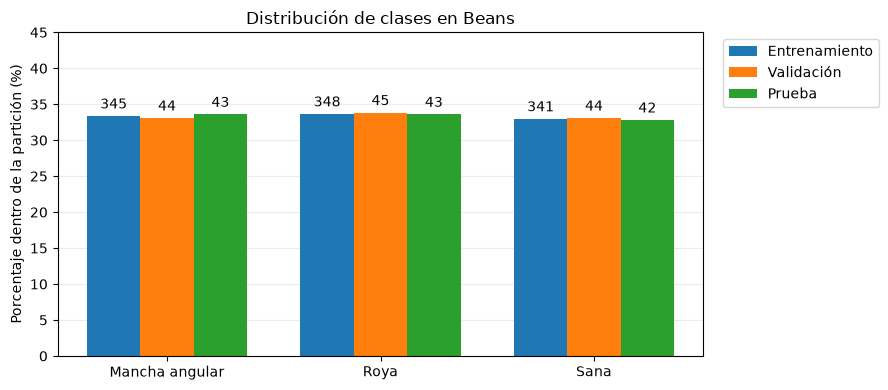

In [9]:
# PASO 3.2: Visualizar la distribución de clases por partición
nombres_clases = ["Mancha angular", "Roya", "Sana"]
posiciones = np.arange(len(clases))
ancho = 0.25

fig, ax = plt.subplots(figsize=(9, 4))

for i, (particion, conteos) in enumerate(conteos_beans.items()):
    porcentajes = 100 * conteos / conteos.sum()
    barras = ax.bar(
        posiciones + (i - 1) * ancho,
        porcentajes,
        width=ancho,
        label=particion,
    )
    ax.bar_label(barras, labels=[str(n) for n in conteos], padding=3)

ax.set_xticks(posiciones, nombres_clases)
ax.set_ylabel("Porcentaje dentro de la partición (%)")
ax.set_ylim(0, 45)
ax.set_title("Distribución de clases en Beans")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

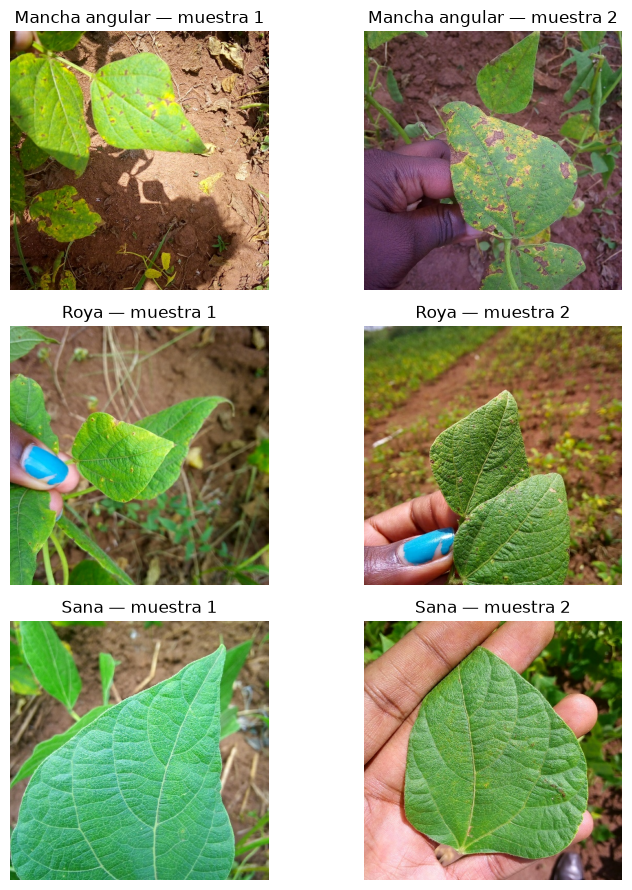

In [10]:
# PASO 4: Visualizar imágenes originales de entrenamiento por clase
muestras_por_clase = [[] for _ in clases]
cantidad_por_clase = 2

# Reunir dos imágenes de cada clase usando solo Train.
for registro in ds_train:
    etiqueta = int(registro["label"].numpy())

    if len(muestras_por_clase[etiqueta]) < cantidad_por_clase:
        muestras_por_clase[etiqueta].append(registro["image"].numpy())

    if all(len(muestras) == cantidad_por_clase for muestras in muestras_por_clase):
        break

# Mostrar cada clase en una fila.
fig, ejes = plt.subplots(len(clases), cantidad_por_clase, figsize=(8, 9))

for fila, (nombre, muestras) in enumerate(zip(nombres_clases, muestras_por_clase)):
    for columna, foto in enumerate(muestras):
        eje = ejes[fila, columna]
        eje.imshow(foto)
        eje.set_title(f"{nombre} — muestra {columna + 1}")
        eje.axis("off")

fig.tight_layout()
plt.show()

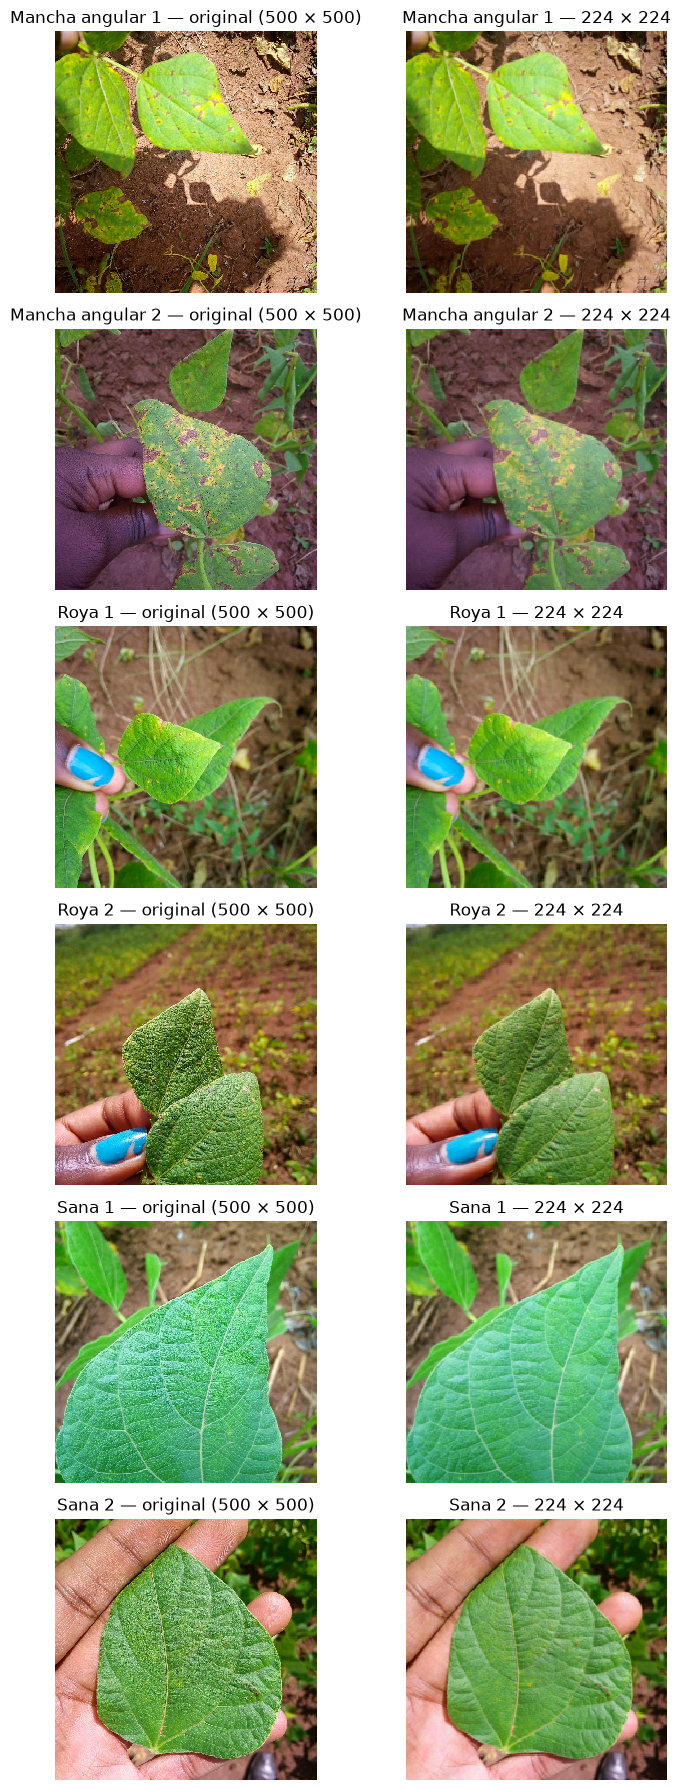

In [11]:
# PASO 4.1: Comparar las imágenes originales con su versión de 224 × 224
cantidad_muestras = sum(len(muestras) for muestras in muestras_por_clase)
fig, ejes = plt.subplots(
    cantidad_muestras, 2, figsize=(8, 3 * cantidad_muestras)
)

fila = 0

for nombre, muestras in zip(nombres_clases, muestras_por_clase):
    for numero, foto in enumerate(muestras, start=1):
        # Reducir la imagen cuadrada conservando toda la foto.
        reducida = tf.image.resize(foto, (224, 224), antialias=True)

        # Convertir a uint8 únicamente para mostrarla con Matplotlib.
        reducida_visible = tf.cast(
            tf.clip_by_value(tf.round(reducida), 0, 255), tf.uint8
        ).numpy()

        alto, ancho = foto.shape[:2]
        ejes[fila, 0].imshow(foto, interpolation="nearest")
        ejes[fila, 0].set_title(
            f"{nombre} {numero} — original ({ancho} × {alto})"
        )
        ejes[fila, 0].axis("off")

        ejes[fila, 1].imshow(reducida_visible, interpolation="nearest")
        ejes[fila, 1].set_title(f"{nombre} {numero} — 224 × 224")
        ejes[fila, 1].axis("off")

        fila += 1

fig.tight_layout()
plt.show()

In [12]:
# PASO 5: Preparación de los datos de Beans para el entrenamiento
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def preparar_imagen(registro):
    # Aplicar la misma reducción que se revisó en el Paso 4.1.
    imagen = tf.image.resize(registro["image"], IMG_SIZE, antialias=True)
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, registro["label"]


def preparar_dataset(dataset, cantidad, entrenamiento=False):
    # Informar a TensorFlow cuántas imágenes entrega la partición.
    dataset = dataset.apply(tf.data.experimental.assert_cardinality(cantidad))

    # Mezclar Train antes de formar los lotes.
    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=cantidad, seed=42, reshuffle_each_iteration=True
        )

    dataset = dataset.map(preparar_imagen, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_preparado = preparar_dataset(ds_train, cantidad_train, entrenamiento=True)
val_preparado = preparar_dataset(ds_val, cantidad_val)
test_preparado = preparar_dataset(ds_test, cantidad_test)

# Verificar un lote de Train y uno de Validation.
for nombre, dataset in [
    ("Entrenamiento", train_preparado),
    ("Validación", val_preparado),
]:
    imagenes, etiquetas = next(iter(dataset))
    print(f"\n{nombre}")
    print("Dimensiones de las imágenes:", imagenes.shape)
    print("Dimensiones de las etiquetas:", etiquetas.shape)
    print("Tipo de píxeles:", imagenes.dtype.name)


Entrenamiento
Dimensiones de las imágenes: (32, 224, 224, 3)
Dimensiones de las etiquetas: (32,)
Tipo de píxeles: float32

Validación
Dimensiones de las imágenes: (32, 224, 224, 3)
Dimensiones de las etiquetas: (32,)
Tipo de píxeles: float32


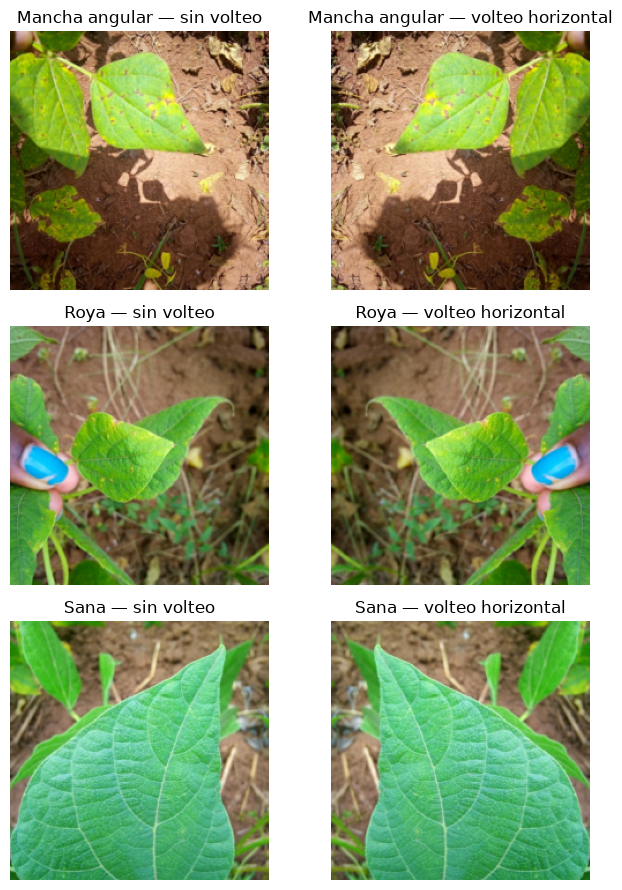

In [13]:
# PASO 6: Inspección visual del volteo horizontal en imágenes de Train
fig, ejes = plt.subplots(len(clases), 2, figsize=(7, 9))

for fila, (nombre, muestras) in enumerate(zip(nombres_clases, muestras_por_clase)):
    foto = tf.image.resize(muestras[0], IMG_SIZE, antialias=True)

    # Convertir a uint8 para mostrar la foto con sus colores.
    foto = tf.cast(tf.clip_by_value(tf.round(foto), 0, 255), tf.uint8)
    volteada = tf.image.flip_left_right(foto)

    ejes[fila, 0].imshow(foto.numpy())
    ejes[fila, 0].set_title(f"{nombre} — sin volteo")
    ejes[fila, 1].imshow(volteada.numpy())
    ejes[fila, 1].set_title(f"{nombre} — volteo horizontal")

    for eje in ejes[fila]:
        eje.axis("off")

fig.tight_layout()
plt.show()

In [14]:
# PASO 7: Crear una variante de Train con volteo horizontal aleatorio
volteo_horizontal = tf.keras.layers.RandomFlip(
    mode="horizontal",
    seed=42,
)

def aplicar_volteo(imagenes, etiquetas):
    # Aplicar el aumento a las imágenes y conservar sus etiquetas.
    return volteo_horizontal(imagenes, training=True), etiquetas

train_con_aumento = train_preparado.map(aplicar_volteo).prefetch(tf.data.AUTOTUNE)

print("Lotes de Train sin aumento:", int(train_preparado.cardinality().numpy()))
print("Lotes de Train con aumento:", int(train_con_aumento.cardinality().numpy()))

Lotes de Train sin aumento: 33
Lotes de Train con aumento: 33
